# Reinforcement Learning w alokacji portfela

## Financial Decision Support System — eksperyment PPO

Notebook analizuje eksperymentalne zastosowanie Reinforcement Learning
do dynamicznej alokacji portfela.

W eksperymencie wykorzystano algorytm **Proximal Policy Optimization (PPO)**.

Celem analizy jest sprawdzenie:

- jak agent dynamicznie zmienia wagi aktywów;
- jaki wynik osiąga na zbiorze walidacyjnym;
- jaki poziom ryzyka generuje;
- jaki jest wpływ kosztów transakcyjnych i rotacji portfela;
- czy PPO uzyskuje przewagę nad prostszymi strategiami referencyjnymi.

Notebook nie trenuje ponownie agenta.
Wykorzystuje zapisany model oraz artefakty wygenerowane przez backend.

## 1. Zasady metodologiczne

Eksperyment RL jest traktowany jako rozszerzenie badawcze,
a nie jako główny mechanizm alokacji systemu.

Obowiązują następujące zasady:

- agent PPO jest trenowany wyłącznie na zbiorze treningowym;
- ocena odbywa się na zbiorze walidacyjnym;
- końcowy test split pozostaje zamknięty;
- koszty transakcyjne są uwzględniane w środowisku;
- agent podlega ograniczeniu maksymalnej wagi pojedynczego aktywa;
- wynik PPO jest porównywany z klasycznymi strategiami portfelowymi;
- większa złożoność modelu nie jest traktowana jako dowód jego przewagi.

Celem eksperymentu jest ocena zachowania polityki RL,
a nie wykazanie przewagi PPO za wszelką cenę.

In [23]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [ ]:
def find_project_root(
    start: Path | None = None,
) -> Path:
    candidate = (start or Path.cwd()).resolve()

    for path in [
        candidate,
        *candidate.parents,
    ]:
        if (path / "pyproject.toml").exists() and (path / "backend").exists():
            return path

    raise FileNotFoundError("Nie znaleziono katalogu głównego projektu.")


PROJECT_ROOT = find_project_root()

RL_DIR = PROJECT_ROOT / "benchmark_results" / "rl" / "ppo"

RL_RESULT_PATH = RL_DIR / "rl_result.json"

print("Katalog projektu:")
print(PROJECT_ROOT)

print("\nArtefakty RL:")
for path in sorted(RL_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)

Katalog projektu:
project-root

Artefakty RL:
- ppo_allocation_agent.zip
- rl_result.json
- rl_summary.csv
- rl_trajectory.csv
- rl_weights.csv


## 2. Wczytanie artefaktu eksperymentu

Głównym źródłem informacji jest `rl_result.json`.

Dodatkowe pliki CSV zawierają:

- porównanie strategii;
- trajektorię walidacyjną PPO;
- dynamiczne wagi portfela.

Notebook korzysta z zapisanych wyników i nie uruchamia ponownie treningu.

In [ ]:
rl_result = json.loads(RL_RESULT_PATH.read_text(encoding="utf-8"))

rl_summary = pd.read_csv(RL_DIR / "rl_summary.csv")

rl_trajectory = pd.read_csv(RL_DIR / "rl_trajectory.csv")

rl_weights = pd.read_csv(RL_DIR / "rl_weights.csv")

print(
    "Strategie:",
    len(rl_summary),
)

print(
    "Obserwacje trajektorii:",
    len(rl_trajectory),
)

print(
    "Obserwacje wag:",
    len(rl_weights),
)

Strategie: 4
Obserwacje trajektorii: 566
Obserwacje wag: 566


## 3. Provenance i kontrola test splitu

Przed analizą wyników sprawdzamy, czy artefakt RL odpowiada
przyjętej metodologii projektu.

Oczekujemy:

- modelu `ppo`;
- treningu na `training`;
- ewaluacji na `validation`;
- braku wykorzystania końcowego test splitu.

In [ ]:
assert rl_result["model_name"] == "ppo"

assert rl_result["training_split"] == "training"

assert rl_result["evaluation_split"] == "validation"

assert rl_result["test_split_used"] is False

print(
    "Model:",
    rl_result["model_name"],
)

print(
    "Training split:",
    rl_result["training_split"],
)

print(
    "Evaluation split:",
    rl_result["evaluation_split"],
)

print(
    "Liczba obserwacji treningowych:",
    rl_result["training_observations"],
)

print(
    "Test split użyty:",
    rl_result["test_split_used"],
)

print("\nKońcowy test split pozostaje zamknięty.")

Model: ppo
Training split: training
Evaluation split: validation
Liczba obserwacji treningowych: 1837
Test split użyty: False

Końcowy test split pozostaje zamknięty.


## 4. Konfiguracja agenta PPO

Konfiguracja agenta określa parametry procesu uczenia,
między innymi:

- liczbę kroków treningowych;
- learning rate;
- rozmiar batcha;
- współczynnik dyskontowania;
- parametry PPO;
- architekturę sieci;
- seed;
- urządzenie obliczeniowe.

Parametry pochodzą bezpośrednio z zapisanego artefaktu eksperymentu.

In [ ]:
agent_config = pd.DataFrame(
    [
        {
            "Parametr": key,
            "Wartość": value,
        }
        for key, value in rl_result["agent_config"].items()
    ]
)

display(agent_config)

,Parametr,Wartość
0,total_timesteps,10000
1,learning_rate,0.0003
2,n_steps,256
3,batch_size,64
4,n_epochs,10
5,gamma,0.99
6,gae_lambda,0.95
7,clip_range,0.2
8,entropy_coefficient,0.0
9,hidden_layer_sizes,"[64, 64]"


## 5. Konfiguracja środowiska portfolio allocation

Środowisko RL modeluje dynamiczną alokację kapitału
pomiędzy analizowane aktywa.

Konfiguracja obejmuje:

- długość okna historycznego;
- koszt transakcyjny;
- karę za drawdown;
- maksymalną wagę pojedynczego aktywa;
- początkową wartość portfela.

Uwzględnienie kosztów i ograniczeń jest ważne,
ponieważ polityka RL bez takich mechanizmów mogłaby
generować nierealistyczną rotację portfela.

In [ ]:
environment_config = pd.DataFrame(
    [
        {
            "Parametr": key,
            "Wartość": value,
        }
        for key, value in rl_result["environment_config"].items()
    ]
)

display(environment_config)

,Parametr,Wartość
0,lookback_window,20.00
1,transaction_cost_bps,10.00
2,drawdown_penalty,0.25
3,max_weight,0.35
4,initial_portfolio_value,1.00


## 6. Wynik walidacyjny PPO

Po zakończeniu treningu polityka PPO została oceniona
na chronologicznie późniejszym zbiorze walidacyjnym.

Analizujemy:

- skumulowany zwrot;
- końcową wartość portfela;
- zwrot i zmienność;
- Sharpe i Sortino;
- maximum drawdown;
- koszty transakcyjne;
- rotację portfela;
- przebieg funkcji nagrody.

Wynik walidacyjny nie jest wynikiem końcowego testu.

In [29]:
evaluation = rl_result["evaluation"]

evaluation_overview = pd.DataFrame(
    [
        {
            "Miara": "Obserwacje",
            "Wartość": evaluation["observations"],
        },
        {
            "Miara": "Początek walidacji",
            "Wartość": evaluation["date_min"],
        },
        {
            "Miara": "Koniec walidacji",
            "Wartość": evaluation["date_max"],
        },
        {
            "Miara": "Skumulowany zwrot",
            "Wartość": evaluation["cumulative_return"],
        },
        {
            "Miara": "Końcowa wartość portfela",
            "Wartość": evaluation["final_portfolio_value"],
        },
        {
            "Miara": "Łączna nagroda",
            "Wartość": evaluation["total_reward"],
        },
        {
            "Miara": "Łączny koszt transakcyjny",
            "Wartość": evaluation["total_transaction_cost"],
        },
        {
            "Miara": "Średni turnover",
            "Wartość": evaluation["mean_turnover"],
        },
    ]
)

display(evaluation_overview)

,Miara,Wartość
0,Obserwacje,566
1,Początek walidacji,2022-01-25
2,Koniec walidacji,2024-04-25
3,Skumulowany zwrot,0.260157
4,Końcowa wartość portfela,1.260157
5,Łączna nagroda,-16.245672
6,Łączny koszt transakcyjny,0.005659
7,Średni turnover,0.009998


In [ ]:
risk_metrics = pd.DataFrame(
    [
        {
            "Miara": key,
            "Wartość": value,
        }
        for key, value in evaluation["risk_metrics"].items()
    ]
)

display(risk_metrics)

,Miara,Wartość
0,annualized_mean_return,0.119135
1,annualized_volatility,0.179715
2,sharpe_ratio,0.552718
3,sortino_ratio,0.777954
4,value_at_risk,0.016160
5,conditional_value_at_risk,0.025150
6,maximum_drawdown,0.301418


### Interpretacja wyniku PPO

Na zbiorze walidacyjnym PPO osiągnęło dodatni skumulowany zwrot,
ale sam zwrot nie wystarcza do oceny polityki.

W analizie RL należy jednocześnie uwzględnić:

- ryzyko;
- drawdown;
- stabilność wartości portfela;
- rotację aktywów;
- koszty transakcyjne;
- funkcję nagrody.

Wartość `total_reward` nie jest bezpośrednim odpowiednikiem
stopy zwrotu. Funkcja nagrody może zawierać kary związane
z ryzykiem, drawdownem lub innymi ograniczeniami środowiska.

## 7. Trajektoria portfela na walidacji

Plik `rl_trajectory.csv` przechowuje przebieg całego epizodu walidacyjnego.

Dla każdej sesji dostępne są:

- gross return;
- koszt transakcyjny;
- net return;
- turnover;
- wartość portfela;
- drawdown;
- reward.

Pozwala to analizować zachowanie polityki w czasie,
a nie wyłącznie końcową wartość metryk.

In [ ]:
trajectory = rl_trajectory.copy()

trajectory["date"] = pd.to_datetime(trajectory["date"])

trajectory = trajectory.sort_values("date").reset_index(drop=True)

display(trajectory.head())

print(
    "Zakres:",
    trajectory["date"].min().date(),
    "→",
    trajectory["date"].max().date(),
)

,date,gross_return,transaction_cost,net_return,turnover,portfolio_value,drawdown,reward
0,2022-01-25,-0.004495,0.000160,-0.004655,0.160472,0.995345,0.004655,-0.005830
1,2022-01-26,-0.004183,0.000007,-0.004190,0.006585,0.991174,0.008826,-0.006405
2,2022-01-27,-0.003332,0.000011,-0.003343,0.010909,0.987861,0.012139,-0.006384
3,2022-01-28,0.011092,0.000006,0.011086,0.006165,0.998812,0.001188,0.010728
4,2022-01-31,0.014748,0.000001,0.014747,0.001425,1.013541,0.000000,0.014639


Zakres: 2022-01-25 → 2024-04-25


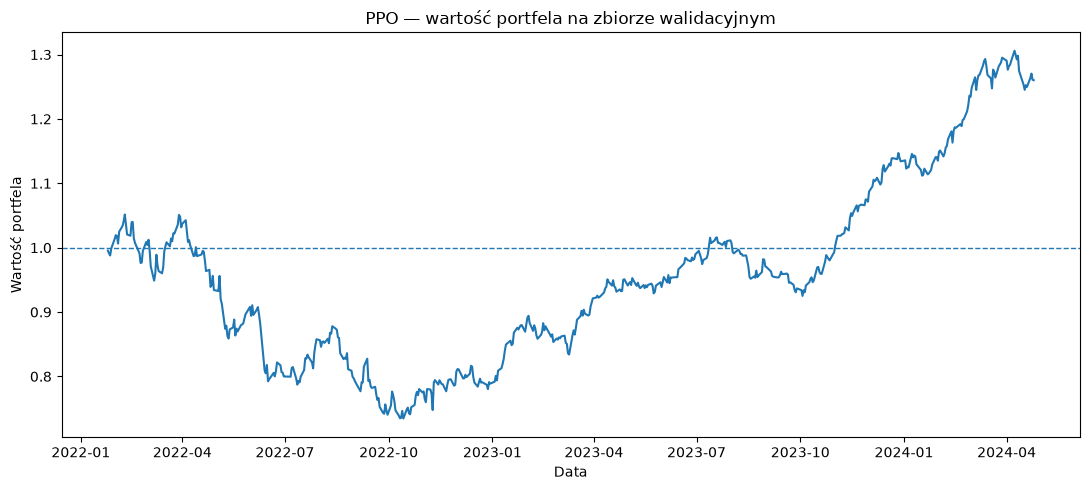

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    trajectory["date"],
    trajectory["portfolio_value"],
)

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Data")

plt.ylabel("Wartość portfela")

plt.title("PPO — wartość portfela na zbiorze walidacyjnym")

plt.tight_layout()

plt.show()

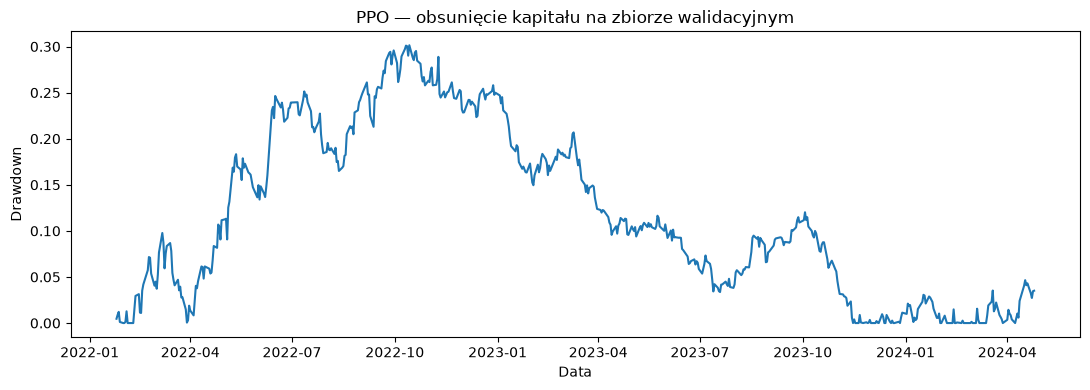

In [ ]:
plt.figure(figsize=(11, 4))

plt.plot(
    trajectory["date"],
    trajectory["drawdown"],
)

plt.xlabel("Data")

plt.ylabel("Drawdown")

plt.title("PPO — obsunięcie kapitału na zbiorze walidacyjnym")

plt.tight_layout()

plt.show()

### Interpretacja trajektorii

Dodatni wynik końcowy nie oznacza, że ścieżka portfela
była stabilna.

Drawdown pokazuje skalę spadku wartości portfela
względem wcześniejszego maksimum.

W przypadku strategii inwestycyjnej istotne jest więc
nie tylko to, gdzie kończy się portfel, ale także
jak duże obsunięcia występują po drodze.

In [ ]:
trajectory["cumulative_transaction_cost"] = trajectory["transaction_cost"].cumsum()

cost_summary = pd.DataFrame(
    [
        {
            "Miara": "Łączny koszt transakcyjny",
            "Wartość": trajectory["transaction_cost"].sum(),
        },
        {
            "Miara": "Średni turnover",
            "Wartość": trajectory["turnover"].mean(),
        },
        {
            "Miara": "Maksymalny turnover",
            "Wartość": trajectory["turnover"].max(),
        },
    ]
)

display(cost_summary)

,Miara,Wartość
0,Łączny koszt transakcyjny,0.005659
1,Średni turnover,0.009998
2,Maksymalny turnover,0.160472


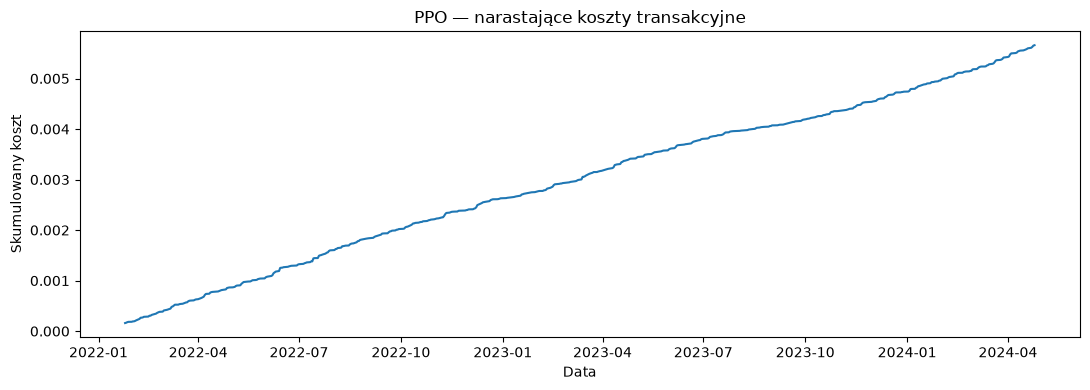

In [ ]:
plt.figure(figsize=(11, 4))

plt.plot(
    trajectory["date"],
    trajectory["cumulative_transaction_cost"],
)

plt.xlabel("Data")

plt.ylabel("Skumulowany koszt")

plt.title("PPO — narastające koszty transakcyjne")

plt.tight_layout()

plt.show()

## 8. Dynamiczna alokacja aktywów

W przeciwieństwie do statycznych portfeli klasycznych,
PPO może zmieniać alokację w kolejnych krokach środowiska.

Plik `rl_weights.csv` pozwala sprawdzić:

- czy agent rzeczywiście zmienia strukturę portfela;
- które aktywa otrzymują najwyższe przeciętne wagi;
- jak stabilne są decyzje polityki;
- czy przestrzegane jest ograniczenie maksymalnej wagi.

In [ ]:
weights = rl_weights.copy()

weights["date"] = pd.to_datetime(weights["date"])

asset_columns = [column for column in weights.columns if column != "date"]

weight_summary = pd.DataFrame(
    {
        "Instrument": asset_columns,
        "Średnia waga": [weights[column].mean() for column in asset_columns],
        "Minimalna waga": [weights[column].min() for column in asset_columns],
        "Maksymalna waga": [weights[column].max() for column in asset_columns],
    }
).sort_values(
    "Średnia waga",
    ascending=False,
)

display(weight_summary)

,Instrument,Średnia waga,Minimalna waga,Maksymalna waga
0,AGG,0.194501,0.154586,0.229681
1,BTC-USD,0.162773,0.153290,0.170277
5,SPY,0.140164,0.094713,0.173601
4,QQQ,0.131259,0.113070,0.138863
3,GLD,0.122646,0.065129,0.181780
2,EPOL,0.115116,0.077466,0.182181
6,VGK,0.071187,0.064894,0.077345
7,VT,0.062354,0.054648,0.071780


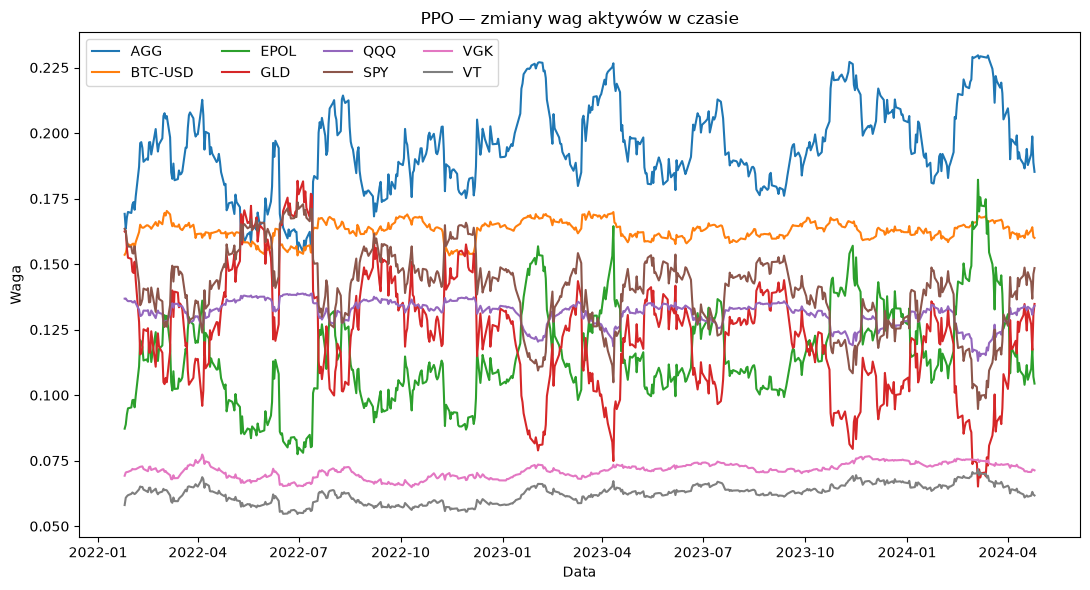

In [ ]:
plt.figure(figsize=(11, 6))

for asset in asset_columns:
    plt.plot(
        weights["date"],
        weights[asset],
        label=asset,
    )

plt.xlabel("Data")

plt.ylabel("Waga")

plt.title("PPO — zmiany wag aktywów w czasie")

plt.legend(
    ncol=4,
)

plt.tight_layout()

plt.show()

In [ ]:
weight_sums = weights[asset_columns].sum(axis=1)

print(
    "Minimalna suma wag:",
    weight_sums.min(),
)

print(
    "Maksymalna suma wag:",
    weight_sums.max(),
)

print(
    "Najwyższa zaobserwowana waga:",
    weights[asset_columns].max().max(),
)

print(
    "Limit środowiska:",
    rl_result["environment_config"]["max_weight"],
)

Minimalna suma wag: 0.9999999999999993
Maksymalna suma wag: 1.0000000000000002
Najwyższa zaobserwowana waga: 0.229680822210312
Limit środowiska: 0.35


## 9. PPO na tle klasycznych strategii

Sama ocena PPO nie pozwala stwierdzić, czy zastosowanie
Reinforcement Learning wnosi wartość względem prostszych metod.

Dlatego polityka PPO jest porównywana ze strategiami referencyjnymi
ocenionymi na tym samym zbiorze walidacyjnym.

Porównanie obejmuje:

- annualizowany zwrot;
- annualizowaną zmienność;
- Sharpe ratio;
- Sortino ratio;
- Value at Risk;
- Conditional Value at Risk;
- maximum drawdown;
- skumulowany zwrot.

Wszystkie strategie muszą być oceniane na tym samym okresie,
aby porównanie było metodologicznie spójne.

In [ ]:
comparison_columns = [
    "strategy",
    "strategy_type",
    "construction",
    "evaluation_split",
    "observations",
    "annualized_mean_return",
    "annualized_volatility",
    "sharpe_ratio",
    "sortino_ratio",
    "value_at_risk",
    "conditional_value_at_risk",
    "maximum_drawdown",
    "cumulative_return",
]

comparison_table = rl_summary[comparison_columns].copy()

display(comparison_table)

,strategy,strategy_type,construction,evaluation_split,observations,annualized_mean_return,annualized_volatility,sharpe_ratio,sortino_ratio,value_at_risk,conditional_value_at_risk,maximum_drawdown,cumulative_return
0,ppo,reinforcement_learning,dynamic_ppo_allocation,validation,566,0.119135,0.179715,0.552718,0.777954,0.016160,0.025150,0.301418,0.260157
1,equal_weight,fixed_portfolio,manual_equal_weight,validation,566,0.120753,0.179376,0.562783,0.798614,0.016251,0.025082,0.293717,0.264959
2,maximum_sharpe,fixed_portfolio,optimized_on_training_maximum_sharpe,validation,566,0.112680,0.164176,0.565717,0.799998,0.014868,0.022868,0.278606,0.249523
3,minimum_volatility,fixed_portfolio,optimized_on_training_minimum_volatility,validation,566,0.051922,0.095077,0.337819,0.492845,0.009421,0.012574,0.153050,0.112362


In [ ]:
assert (comparison_table["evaluation_split"] == "validation").all()

assert (
    comparison_table["observations"] == comparison_table["observations"].iloc[0]
).all()

print(
    "Wszystkie strategie oceniono na:",
    comparison_table["evaluation_split"].iloc[0],
)

print(
    "Liczba obserwacji dla każdej strategii:",
    comparison_table["observations"].iloc[0],
)

Wszystkie strategie oceniono na: validation
Liczba obserwacji dla każdej strategii: 566


### Zwrot i zmienność

Pierwszym krokiem jest porównanie relacji pomiędzy
oczekiwanym zwrotem a ryzykiem mierzonym zmiennością.

Wyższy zwrot sam w sobie nie oznacza lepszej strategii,
jeżeli wymaga znacznie większej ekspozycji na ryzyko.

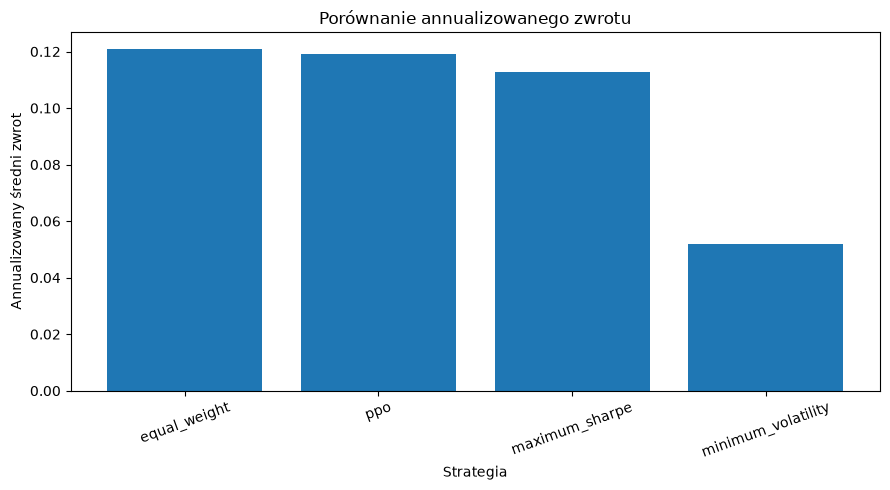

In [ ]:
return_comparison = comparison_table.sort_values(
    "annualized_mean_return",
    ascending=False,
)

plt.figure(figsize=(9, 5))

plt.bar(
    return_comparison["strategy"],
    return_comparison["annualized_mean_return"],
)

plt.xlabel("Strategia")

plt.ylabel("Annualizowany średni zwrot")

plt.title("Porównanie annualizowanego zwrotu")

plt.xticks(
    rotation=20,
)

plt.tight_layout()

plt.show()

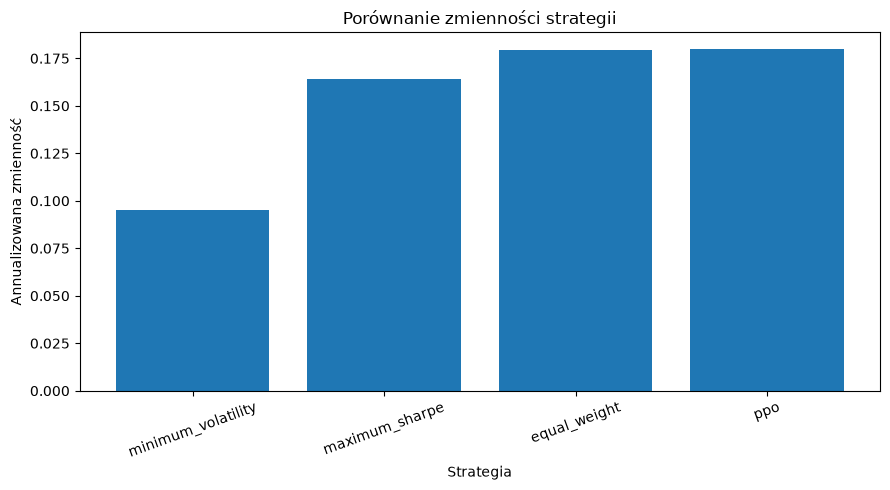

In [ ]:
volatility_comparison = comparison_table.sort_values("annualized_volatility")

plt.figure(figsize=(9, 5))

plt.bar(
    volatility_comparison["strategy"],
    volatility_comparison["annualized_volatility"],
)

plt.xlabel("Strategia")

plt.ylabel("Annualizowana zmienność")

plt.title("Porównanie zmienności strategii")

plt.xticks(
    rotation=20,
)

plt.tight_layout()

plt.show()

### Sharpe i Sortino

Współczynniki Sharpe i Sortino pozwalają ocenić wyniki
strategii po uwzględnieniu ryzyka.

Sharpe odnosi nadwyżkowy zwrot do całkowitej zmienności,
natomiast Sortino koncentruje się na niekorzystnej części
rozkładu zwrotów.

Dzięki temu możliwe jest sprawdzenie, czy bardziej złożona
polityka PPO rzeczywiście poprawia relację zwrotu do ryzyka.

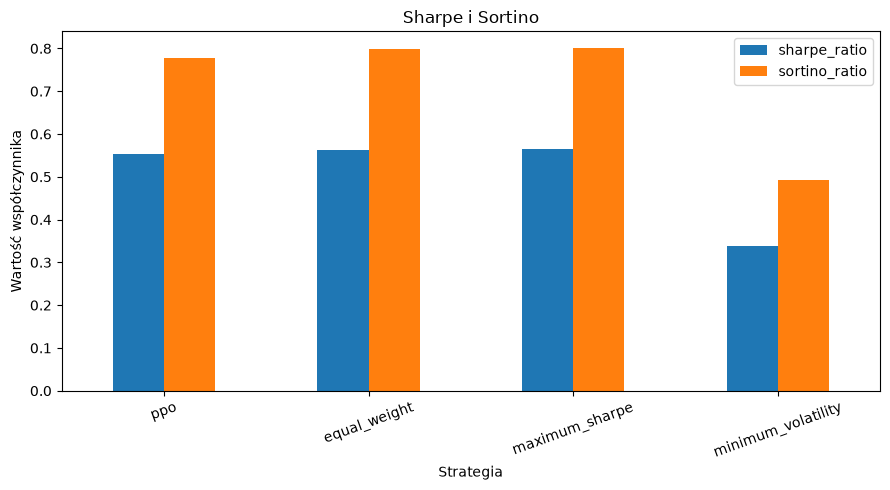

In [ ]:
risk_adjusted = comparison_table[
    [
        "strategy",
        "sharpe_ratio",
        "sortino_ratio",
    ]
].set_index("strategy")

risk_adjusted.plot(
    kind="bar",
    figsize=(9, 5),
)

plt.xlabel("Strategia")

plt.ylabel("Wartość współczynnika")

plt.title("Sharpe i Sortino")

plt.xticks(
    rotation=20,
)

plt.tight_layout()

plt.show()

### Maximum drawdown

Maximum drawdown mierzy największe obsunięcie wartości portfela
od wcześniejszego maksimum.

Jest to szczególnie istotne w analizie strategii dynamicznych,
ponieważ dodatni końcowy zwrot może ukrywać okresy znacznych strat.

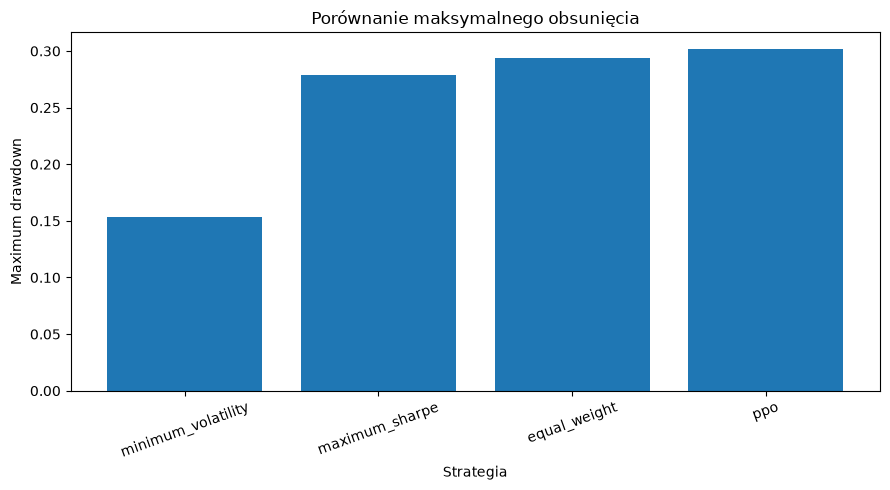

In [ ]:
drawdown_comparison = comparison_table.sort_values("maximum_drawdown")

plt.figure(figsize=(9, 5))

plt.bar(
    drawdown_comparison["strategy"],
    drawdown_comparison["maximum_drawdown"],
)

plt.xlabel("Strategia")

plt.ylabel("Maximum drawdown")

plt.title("Porównanie maksymalnego obsunięcia")

plt.xticks(
    rotation=20,
)

plt.tight_layout()

plt.show()

In [ ]:
best_return = comparison_table.loc[comparison_table["annualized_mean_return"].idxmax()]

best_sharpe = comparison_table.loc[comparison_table["sharpe_ratio"].idxmax()]

lowest_volatility = comparison_table.loc[
    comparison_table["annualized_volatility"].idxmin()
]

lowest_drawdown = comparison_table.loc[comparison_table["maximum_drawdown"].idxmin()]

print(
    "Najwyższy annualizowany zwrot:",
    best_return["strategy"],
    f"({best_return['annualized_mean_return']:.2%})",
)

print(
    "Najwyższy Sharpe:",
    best_sharpe["strategy"],
    f"({best_sharpe['sharpe_ratio']:.3f})",
)

print(
    "Najniższa zmienność:",
    lowest_volatility["strategy"],
    f"({lowest_volatility['annualized_volatility']:.2%})",
)

print(
    "Najniższy maximum drawdown:",
    lowest_drawdown["strategy"],
    f"({lowest_drawdown['maximum_drawdown']:.2%})",
)

Najwyższy annualizowany zwrot: equal_weight (12.08%)
Najwyższy Sharpe: maximum_sharpe (0.566)
Najniższa zmienność: minimum_volatility (9.51%)
Najniższy maximum drawdown: minimum_volatility (15.31%)


In [ ]:
ppo_result = comparison_table[comparison_table["strategy"] == "ppo"].iloc[0]

ppo_metrics = pd.DataFrame(
    [
        {
            "Miara": "Annualizowany zwrot",
            "Wartość": ppo_result["annualized_mean_return"],
        },
        {
            "Miara": "Annualizowana zmienność",
            "Wartość": ppo_result["annualized_volatility"],
        },
        {
            "Miara": "Sharpe ratio",
            "Wartość": ppo_result["sharpe_ratio"],
        },
        {
            "Miara": "Sortino ratio",
            "Wartość": ppo_result["sortino_ratio"],
        },
        {
            "Miara": "Maximum drawdown",
            "Wartość": ppo_result["maximum_drawdown"],
        },
        {
            "Miara": "Skumulowany zwrot",
            "Wartość": ppo_result["cumulative_return"],
        },
    ]
)

display(ppo_metrics)

,Miara,Wartość
0,Annualizowany zwrot,0.119135
1,Annualizowana zmienność,0.179715
2,Sharpe ratio,0.552718
3,Sortino ratio,0.777954
4,Maximum drawdown,0.301418
5,Skumulowany zwrot,0.260157


## 10. Interpretacja porównania strategii

Porównanie na zbiorze walidacyjnym nie wskazuje jednoznacznej
przewagi Reinforcement Learning nad klasycznymi metodami alokacji.

Najważniejsze wyniki są następujące:

- `equal_weight` osiąga najwyższy annualizowany średni zwrot: około 12.08%;
- `maximum_sharpe` osiąga najwyższy współczynnik Sharpe: około 0.566;
- `minimum_volatility` charakteryzuje się najniższą zmiennością:
  około 9.51%;
- `minimum_volatility` osiąga również najniższy maximum drawdown:
  około 15.31%;
- PPO osiąga dodatni i konkurencyjny wynik, lecz nie jest najlepszą
  strategią według żadnego z powyższych kryteriów.

PPO osiąga annualizowany zwrot około 11.91% oraz Sharpe około 0.553,
czyli wynik zbliżony do najlepszych strategii referencyjnych.
Jednocześnie jego zmienność wynosi około 17.97%, a maximum drawdown
około 30.14%.

Oznacza to, że większa złożoność polityki RL nie przełożyła się
w obecnym eksperymencie na jednoznaczną przewagę nad klasycznymi
metodami alokacji.

## 11. Znaczenie wyniku PPO

Brak przewagi PPO nie oznacza, że eksperyment RL jest nieudany.

Agent nauczył się dynamicznej polityki alokacji, zachowywał
ograniczenia środowiska oraz osiągnął dodatni wynik na danych
niewykorzystanych podczas treningu.

Eksperyment pokazuje jednak, że elastyczność modelu RL sama w sobie
nie gwarantuje lepszego profilu zwrotu i ryzyka.

W praktyce strategia RL powinna wykazać przewagę nad prostymi
benchmarkami dopiero po uwzględnieniu:

- stabilności wyników w różnych okresach;
- kosztów transakcyjnych;
- drawdown;
- turnover;
- odporności na zmianę parametrów;
- ryzyka overfittingu;
- wyników na całkowicie niewidzianych danych.

Dlatego PPO jest w systemie traktowane jako rozszerzenie
eksperymentalne, a nie domyślna metoda alokacji.

## 12. Ograniczenia eksperymentu RL

Interpretując wyniki należy uwzględnić kilka ograniczeń.

Po pierwsze, PPO zostało wytrenowane na pojedynczym historycznym
zbiorze treningowym i ocenione na jednym okresie walidacyjnym.

Po drugie, wynik polityki może zależeć od hiperparametrów PPO,
konstrukcji funkcji nagrody, długości okna obserwacji oraz ograniczeń
środowiska.

Po trzecie, Reinforcement Learning w finansach jest szczególnie
narażone na niestacjonarność danych. Relacje obserwowane w jednym
reżimie rynkowym nie muszą utrzymywać się w kolejnym.

Po czwarte, większa liczba parametrów i dynamiczne decyzje zwiększają
ryzyko dopasowania do specyfiki okresu treningowego.

Z tego powodu wynik walidacyjny powinien być traktowany jako element
porównania modeli, a nie jako dowód przyszłej skuteczności strategii.

## 13. Wnioski końcowe

Eksperyment pokazuje możliwość zastosowania Proximal Policy
Optimization do dynamicznej alokacji portfela w ramach
Financial Decision Support System.

Agent PPO:

- został wytrenowany wyłącznie na zbiorze treningowym;
- został oceniony na zbiorze walidacyjnym;
- nie wykorzystał końcowego test splitu;
- generował dynamiczne wagi portfela;
- uwzględniał koszty transakcyjne i ograniczenia wag;
- osiągnął dodatni skumulowany zwrot;
- nie uzyskał jednak jednoznacznej przewagi nad strategiami klasycznymi.

Najwyższy zwrot osiągnęło `equal_weight`, najwyższy Sharpe
`maximum_sharpe`, natomiast `minimum_volatility` zapewniło
najniższą zmienność i najmniejszy maximum drawdown.

Wyniki wspierają więc konserwatywny wniosek: PPO jest interesującym
rozszerzeniem badawczym, ale obecny eksperyment nie uzasadnia
zastąpienia nim prostszych i bardziej interpretowalnych metod
alokacji portfela.